In [1]:
import warnings
warnings.filterwarnings('ignore')

# 1.Data understanding and Exploration

In [2]:
import pandas as pd 
import numpy as np

In [3]:
# Reading the dataset
dataset = pd.read_csv("BoomBikes.csv")

In [4]:
dataset.head()


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [5]:
dataset.shape

(731, 16)

In [6]:
dataset.columns

Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='object')

In [7]:
dataset.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [8]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [9]:
# Assigning string values to different seasons instead of numeric values

# 1 - Spring
dataset.loc[(dataset['season'] == 1), 'season'] = 'spring'

# 2 = Summer
dataset.loc[(dataset['season' ] == 2), 'season'] = 'summer'

# 3 - fall
dataset.loc[(dataset['season'] == 3), 'season'] ='fall'

# 4 - winter
dataset.loc[(dataset['season' ] == 4), 'season'] = 'winter'

In [10]:
dataset['season'].astype('category').value_counts().rename("season")

season
fall      188
summer    184
spring    181
winter    178
Name: season, dtype: int64

In [11]:
# 0 - 2018, 1= 2019 : Year
dataset['yr'].astype('category').value_counts().rename("yr")

yr
1    366
0    365
Name: yr, dtype: int64

In [12]:
# Assigning string values to different months instead of numeric values
def object_map_mnths(x):
    return x.map({1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun', 7: 'Jul', 8:'Aug', 9: 'Sept', 10:'0ct', 11: 'Nov', 12: 'Dec'})

In [13]:
dataset[['mnth']]=dataset[['mnth']].apply(object_map_mnths)

In [14]:
dataset['mnth'].astype('category').value_counts()

mnth
0ct     62
Aug     62
Dec     62
Jan     62
May     62
Jul     62
Mar     62
Apr     60
Nov     60
Jun     60
Sept    60
Feb     57
Name: count, dtype: int64

In [15]:
dataset['holiday'].astype('category').value_counts().rename("holiday")

holiday
0    710
1     21
Name: holiday, dtype: int64

In [16]:
def str_map_weekday(x):
    return x.map({1: 'Mon', 2: 'Tues', 3: 'Wed', 4: 'Thurs', 5: 'Fri', 6: 'Sat', 0: 'Sun'})

In [17]:
dataset[['weekday']]=dataset[['weekday']].apply(str_map_weekday)

In [18]:
dataset['weekday'].astype('category').value_counts().rename("weekday")

weekday
Mon      105
Sat      105
Sun      105
Fri      104
Thurs    104
Tues     104
Wed      104
Name: weekday, dtype: int64

In [19]:
dataset['workingday'].astype('category').value_counts().rename('workingday')

workingday
1    500
0    231
Name: workingday, dtype: int64

In [20]:
# 1 - Clear, few clouds, Partly Cloudly
dataset.loc[(dataset['weathersit'] == 1), 'weathersit'] = 'A'

# 2 = Mist, CLoudyl
dataset.loc[(dataset['weathersit'] == 2), 'weathersit'] = 'B'

# 3 = Light Snow, Heavy Rain
dataset.loc[(dataset['weathersit'] == 3), 'weathersit'] = 'C'



In [21]:
dataset['weathersit'].astype('category').value_counts().rename("weathersit")

weathersit
A    463
B    247
C     21
Name: weathersit, dtype: int64

## 2.Data visualisation

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

<Axes: xlabel='temp', ylabel='Density'>

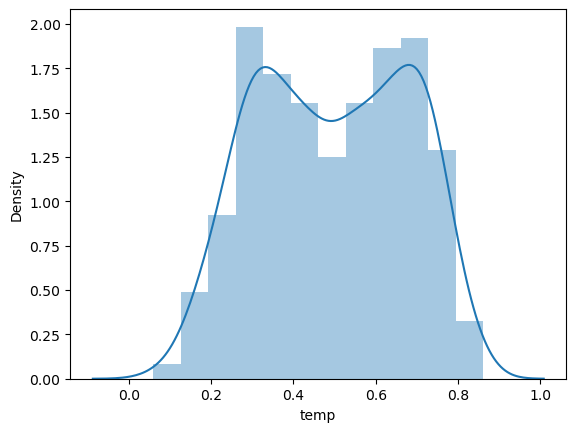

In [23]:
# temperature
sns.distplot(dataset['temp'])

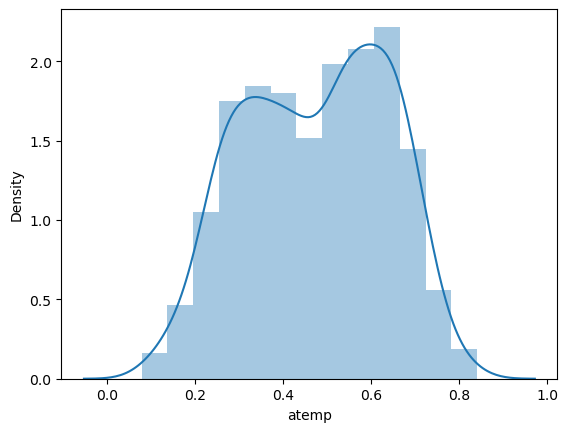

In [24]:
# actual temperature
sns.distplot(dataset['atemp'])
plt.show()

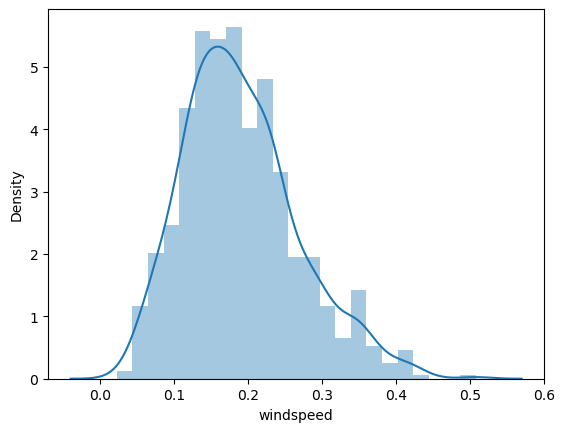

In [25]:
# windspeed
sns.distplot(dataset['windspeed'])
plt.show()

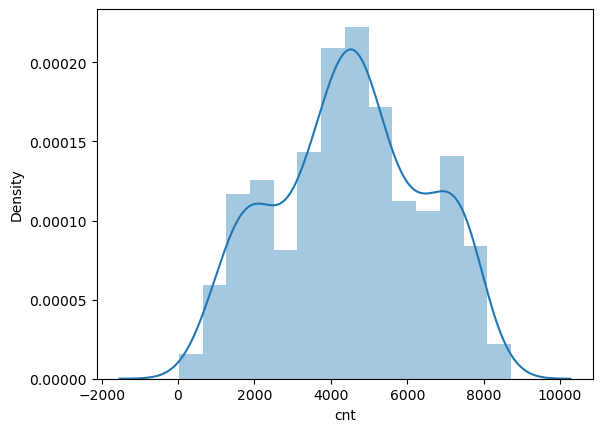

In [26]:
# Target variable: count of total rental bikes including both casual and registered
sns.distplot(dataset['cnt'])
plt.show()

In [27]:
# Converting date to datetime format
dataset['dteday'] = dataset['dteday'].astype('datetime64[ns]')

In [28]:
dataset_categorical = dataset.select_dtypes(exclude=['float64', 'datetime64[ns]','int64'])

In [29]:
dataset_categorical.columns

Index(['season', 'mnth', 'weekday', 'weathersit'], dtype='object')

In [30]:
dataset_categorical

,season,mnth,weekday,weathersit
0,spring,Jan,Sat,B
1,spring,Jan,Sun,B
2,spring,Jan,Mon,A
3,spring,Jan,Tues,A
4,spring,Jan,Wed,A
...,...,...,...,...
726,spring,Dec,Thurs,B
727,spring,Dec,Fri,B
728,spring,Dec,Sat,B
729,spring,Dec,Sun,A


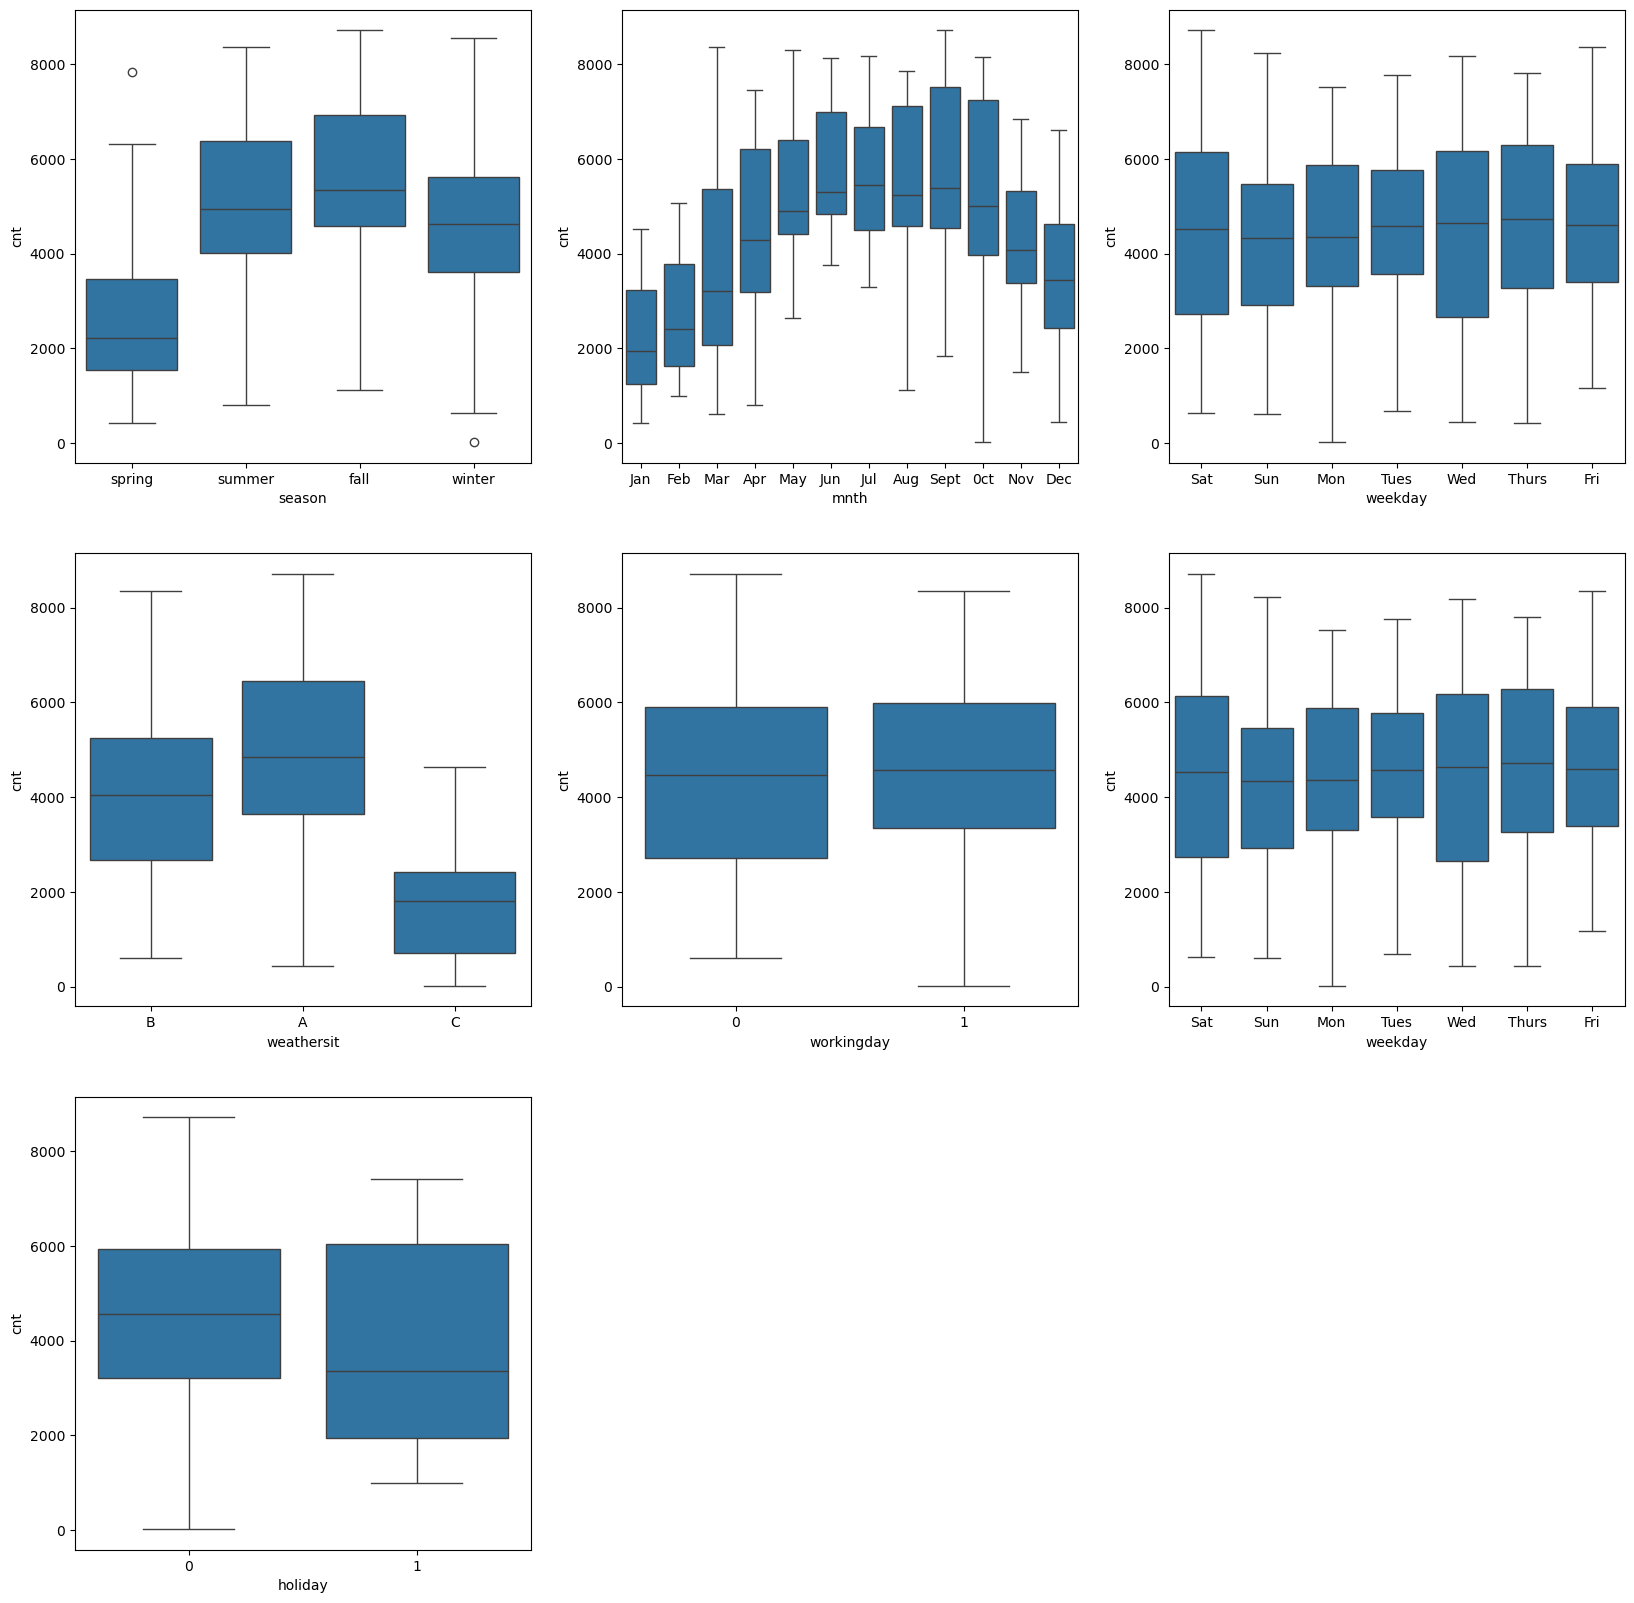

In [31]:

plt.figure(figsize=(20,20))
plt.subplot(3,3,1)
sns.boxplot(x = 'season', y = 'cnt', data=dataset)
plt.subplot(3,3,2)
sns.boxplot(x = 'mnth', y = 'cnt', data=dataset)
plt.subplot(3,3,3) 
sns.boxplot(x = 'weekday', y = 'cnt', data=dataset)
plt.subplot(3,3,4)
sns.boxplot(x = 'weathersit', y = 'cnt', data=dataset)
plt.subplot(3,3,5)
sns.boxplot(x = 'workingday', y = 'cnt', data=dataset)
plt.subplot(3,3,6)
sns.boxplot(x = 'weekday', y = 'cnt', data=dataset)
plt.subplot(3,3,7)
sns.boxplot(x = 'holiday', y = 'cnt', data=dataset)
plt.show()

In [32]:
intVarlist = ["casual", "registered", "cnt"]

for var in intVarlist:
    dataset[var]= dataset[var].astype("float")

In [33]:
dataset_numeric = dataset.select_dtypes(include=['float64'])
dataset_numeric.head()

,temp,atemp,hum,windspeed,casual,registered,cnt
0,0.344167,0.363625,0.805833,0.160446,331.0,654.0,985.0
1,0.363478,0.353739,0.696087,0.248539,131.0,670.0,801.0
2,0.196364,0.189405,0.437273,0.248309,120.0,1229.0,1349.0
3,0.200000,0.212122,0.590435,0.160296,108.0,1454.0,1562.0
4,0.226957,0.229270,0.436957,0.186900,82.0,1518.0,1600.0


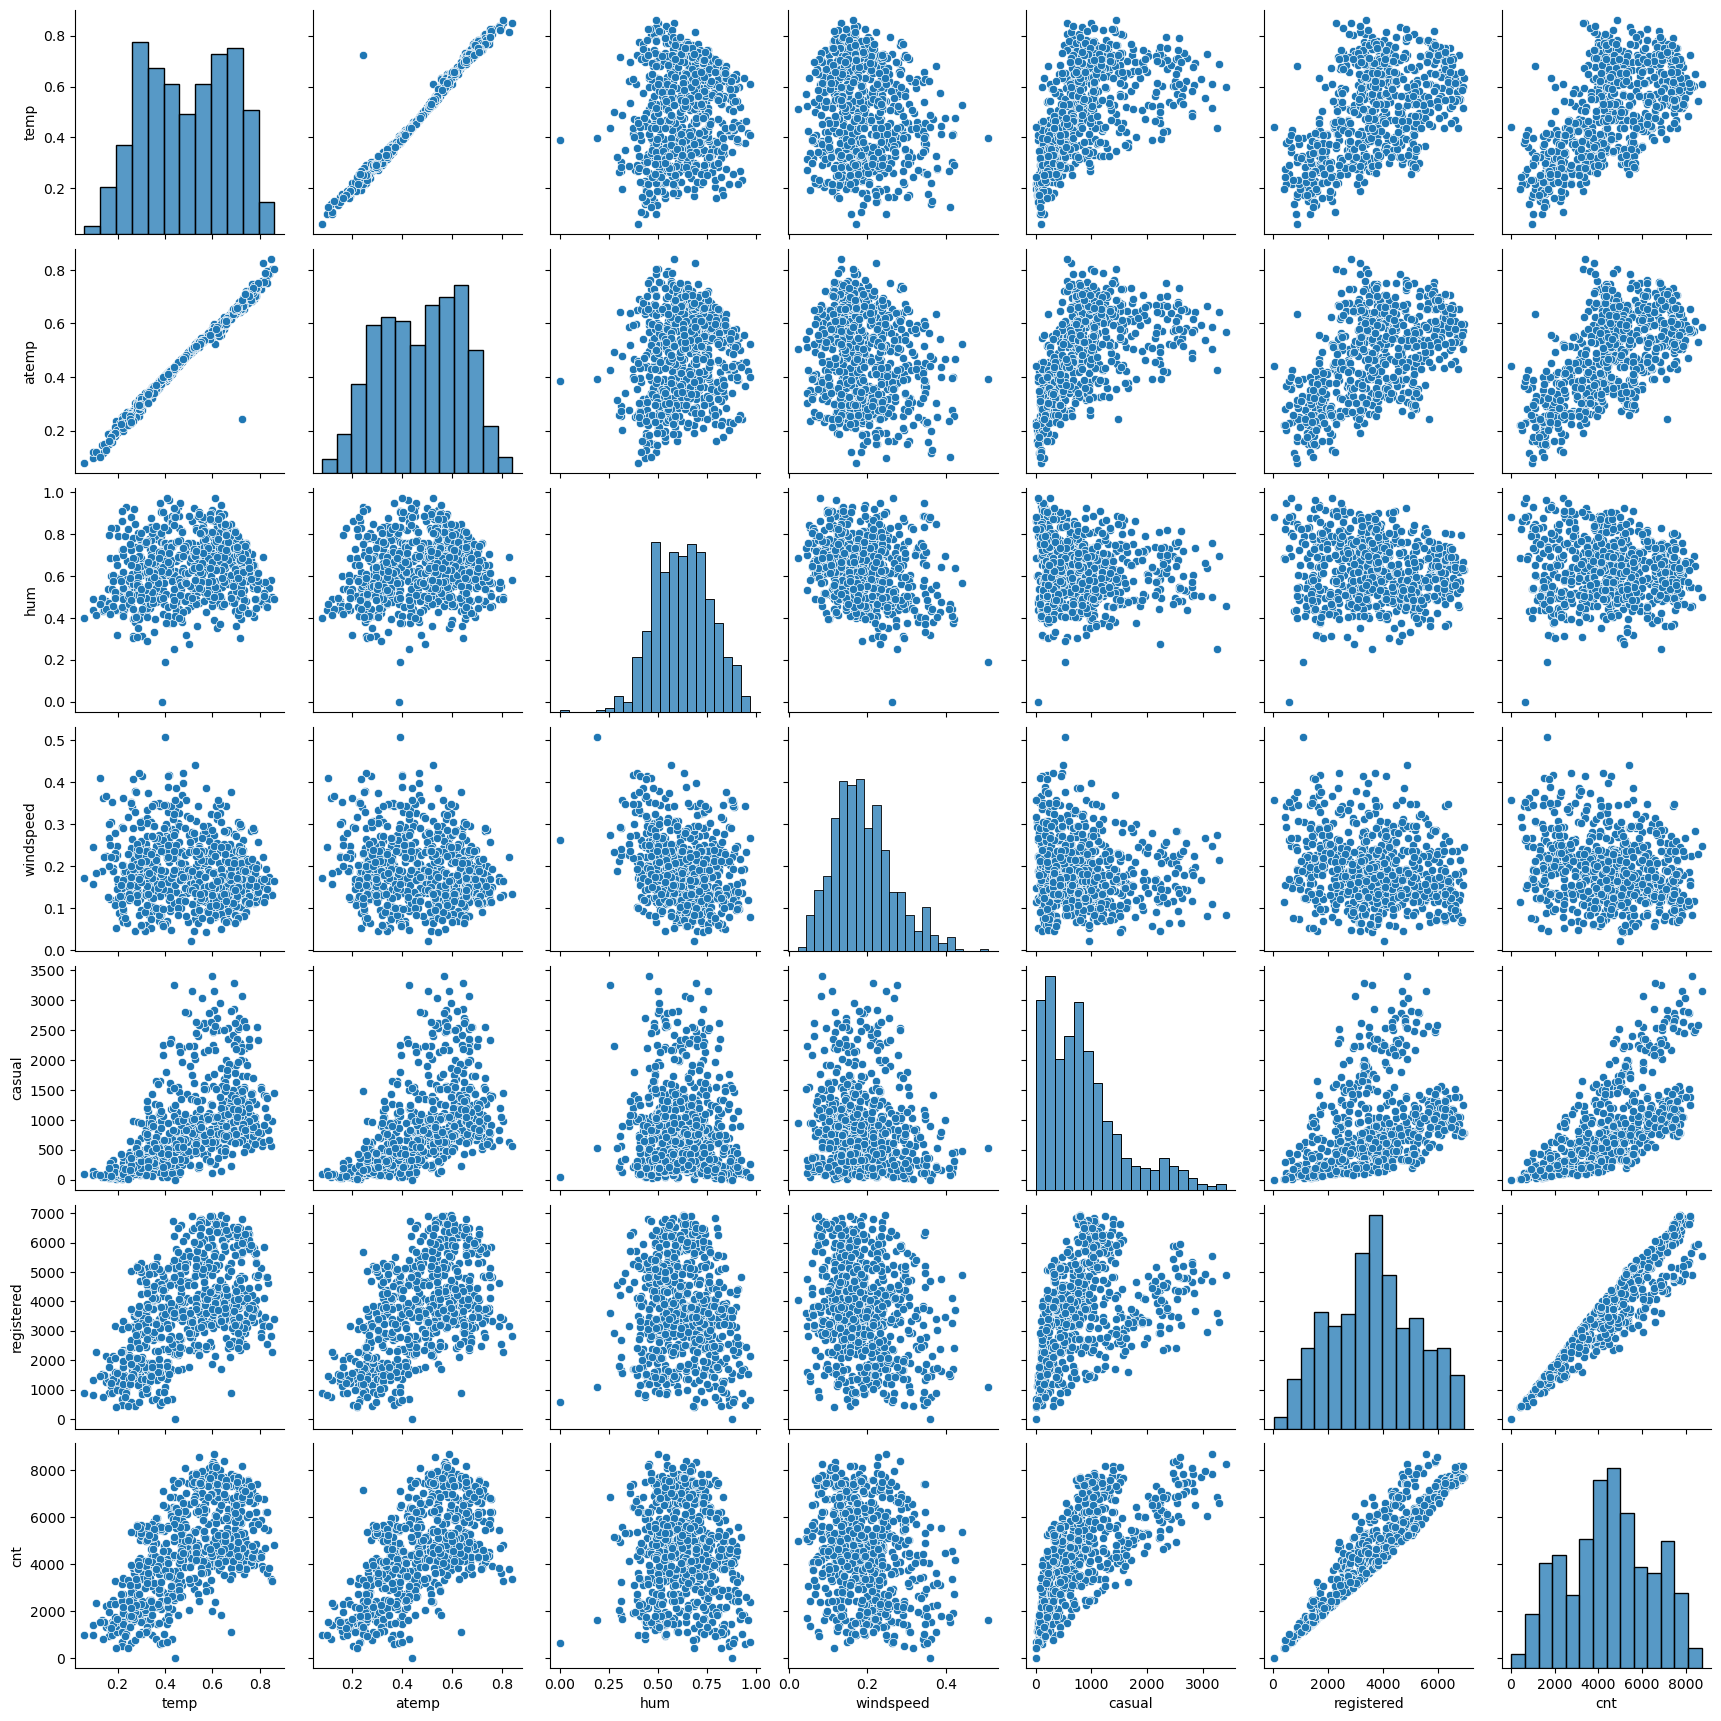

In [34]:
sns.pairplot(dataset_numeric)
plt.show()

In [35]:
cor = dataset.select_dtypes(include=['number']).corr()

In [36]:
cor

,instant,yr,holiday,workingday,temp,atemp,hum,windspeed,casual,registered,cnt
instant,1.000000,0.866025,0.016145,-0.004337,0.150580,0.152638,0.016375,-0.112620,0.275255,0.659623,0.628830
yr,0.866025,1.000000,0.007954,-0.002013,0.047604,0.046106,-0.110651,-0.011817,0.248546,0.594248,0.566710
holiday,0.016145,0.007954,1.000000,-0.253023,-0.028556,-0.032507,-0.015937,0.006292,0.054274,-0.108745,-0.068348
workingday,-0.004337,-0.002013,-0.253023,1.000000,0.052660,0.052182,0.024327,-0.018796,-0.518044,0.303907,0.061156
temp,0.150580,0.047604,-0.028556,0.052660,1.000000,0.991702,0.126963,-0.157944,0.543285,0.540012,0.627494
atemp,0.152638,0.046106,-0.032507,0.052182,0.991702,1.000000,0.139988,-0.183643,0.543864,0.544192,0.631066
hum,0.016375,-0.110651,-0.015937,0.024327,0.126963,0.139988,1.000000,-0.248489,-0.077008,-0.091089,-0.100659
windspeed,-0.112620,-0.011817,0.006292,-0.018796,-0.157944,-0.183643,-0.248489,1.000000,-0.167613,-0.217449,-0.234545
casual,0.275255,0.248546,0.054274,-0.518044,0.543285,0.543864,-0.077008,-0.167613,1.000000,0.395282,0.672804
registered,0.659623,0.594248,-0.108745,0.303907,0.540012,0.544192,-0.091089,-0.217449,0.395282,1.000000,0.945517


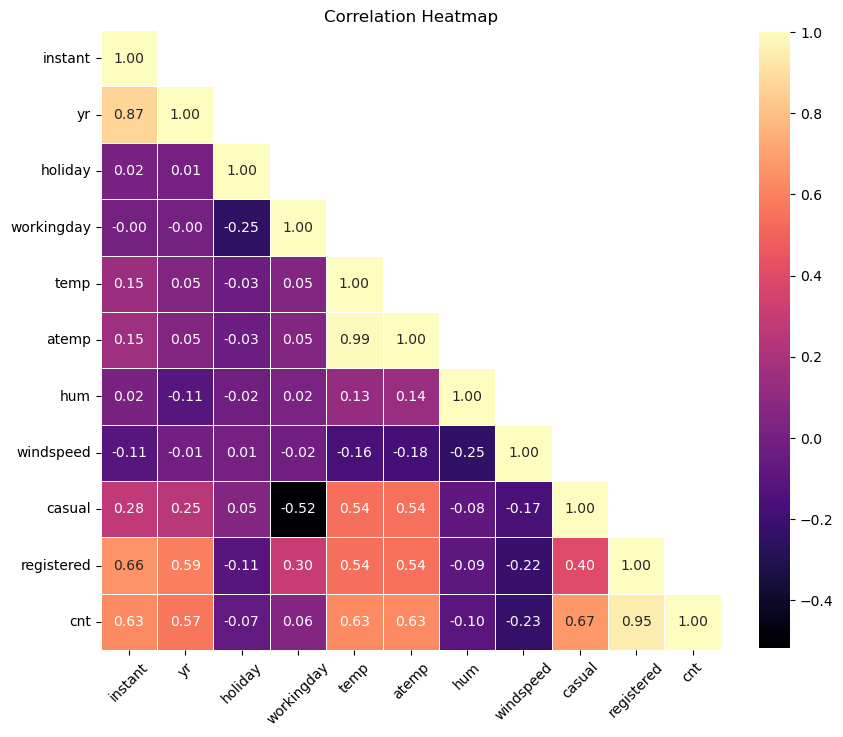

In [37]:
cor = dataset.select_dtypes(include=['number']).corr()
mask = np.triu(np.ones_like(cor, dtype=bool), k=1)
plt.figure(figsize=(10,10))
sns.heatmap(
    cor,
    mask=mask,
    annot=True,
    fmt=".2f",          
    cmap="magma",
    # vmin=-1,
    # vmax=1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)

plt.title("Correlation Heatmap")
plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.show()

In [38]:
# Removinf otemp as it is highly corealed with temp
dataset.drop('atemp', axis=1, inplace=True)

In [39]:
dataset.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,spring,0,Jan,0,Sat,0,B,0.344167,0.805833,0.160446,331.0,654.0,985.0
1,2,2011-01-02,spring,0,Jan,0,Sun,0,B,0.363478,0.696087,0.248539,131.0,670.0,801.0
2,3,2011-01-03,spring,0,Jan,0,Mon,1,A,0.196364,0.437273,0.248309,120.0,1229.0,1349.0
3,4,2011-01-04,spring,0,Jan,0,Tues,1,A,0.200000,0.590435,0.160296,108.0,1454.0,1562.0
4,5,2011-01-05,spring,0,Jan,0,Wed,1,A,0.226957,0.436957,0.186900,82.0,1518.0,1600.0


## 3. Data Preparation

In [40]:
import pandas as pd 
import numpy as np

In [41]:
dataset_categorical = dataset.select_dtypes(include=['object'])

In [42]:
dataset_categorical.head()

,season,mnth,weekday,weathersit
0,spring,Jan,Sat,B
1,spring,Jan,Sun,B
2,spring,Jan,Mon,A
3,spring,Jan,Tues,A
4,spring,Jan,Wed,A


In [43]:
dataset_dummies = pd.get_dummies(dataset_categorical, drop_first = True)
dataset_dummies.head()

,season_spring,season_summer,season_winter,mnth_Apr,mnth_Aug,mnth_Dec,mnth_Feb,mnth_Jan,mnth_Jul,mnth_Jun,...,mnth_Nov,mnth_Sept,weekday_Mon,weekday_Sat,weekday_Sun,weekday_Thurs,weekday_Tues,weekday_Wed,weathersit_B,weathersit_C
0,True,False,False,False,False,False,False,True,False,False,...,False,False,False,True,False,False,False,False,True,False
1,True,False,False,False,False,False,False,True,False,False,...,False,False,False,False,True,False,False,False,True,False
2,True,False,False,False,False,False,False,True,False,False,...,False,False,True,False,False,False,False,False,False,False
3,True,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,True,False,False,False
4,True,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False


In [44]:
# Drop Catergorical variable columns
dataset = dataset.drop(list(dataset_categorical.columns), axis=1)
dataset

,instant,dteday,yr,holiday,workingday,temp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,0,0,0,0.344167,0.805833,0.160446,331.0,654.0,985.0
1,2,2011-01-02,0,0,0,0.363478,0.696087,0.248539,131.0,670.0,801.0
2,3,2011-01-03,0,0,1,0.196364,0.437273,0.248309,120.0,1229.0,1349.0
3,4,2011-01-04,0,0,1,0.200000,0.590435,0.160296,108.0,1454.0,1562.0
4,5,2011-01-05,0,0,1,0.226957,0.436957,0.186900,82.0,1518.0,1600.0
...,...,...,...,...,...,...,...,...,...,...,...
726,727,2012-12-27,1,0,1,0.254167,0.652917,0.350133,247.0,1867.0,2114.0
727,728,2012-12-28,1,0,1,0.253333,0.590000,0.155471,644.0,2451.0,3095.0
728,729,2012-12-29,1,0,0,0.253333,0.752917,0.124383,159.0,1182.0,1341.0
729,730,2012-12-30,1,0,0,0.255833,0.483333,0.350754,364.0,1432.0,1796.0


In [45]:
# Concatenate dummy variables with the dataset
dataset = pd.concat([dataset, dataset_dummies], axis=1)
dataset.head()

,instant,dteday,yr,holiday,workingday,temp,hum,windspeed,casual,registered,...,mnth_Nov,mnth_Sept,weekday_Mon,weekday_Sat,weekday_Sun,weekday_Thurs,weekday_Tues,weekday_Wed,weathersit_B,weathersit_C
0,1,2011-01-01,0,0,0,0.344167,0.805833,0.160446,331.0,654.0,...,False,False,False,True,False,False,False,False,True,False
1,2,2011-01-02,0,0,0,0.363478,0.696087,0.248539,131.0,670.0,...,False,False,False,False,True,False,False,False,True,False
2,3,2011-01-03,0,0,1,0.196364,0.437273,0.248309,120.0,1229.0,...,False,False,True,False,False,False,False,False,False,False
3,4,2011-01-04,0,0,1,0.200000,0.590435,0.160296,108.0,1454.0,...,False,False,False,False,False,False,True,False,False,False
4,5,2011-01-05,0,0,1,0.226957,0.436957,0.186900,82.0,1518.0,...,False,False,False,False,False,False,False,True,False,False


In [46]:
dataset = dataset.drop(['instant', 'dteday'], axis=1, inplace=False)
dataset.head()

,yr,holiday,workingday,temp,hum,windspeed,casual,registered,cnt,season_spring,...,mnth_Nov,mnth_Sept,weekday_Mon,weekday_Sat,weekday_Sun,weekday_Thurs,weekday_Tues,weekday_Wed,weathersit_B,weathersit_C
0,0,0,0,0.344167,0.805833,0.160446,331.0,654.0,985.0,True,...,False,False,False,True,False,False,False,False,True,False
1,0,0,0,0.363478,0.696087,0.248539,131.0,670.0,801.0,True,...,False,False,False,False,True,False,False,False,True,False
2,0,0,1,0.196364,0.437273,0.248309,120.0,1229.0,1349.0,True,...,False,False,True,False,False,False,False,False,False,False
3,0,0,1,0.200000,0.590435,0.160296,108.0,1454.0,1562.0,True,...,False,False,False,False,False,False,True,False,False,False
4,0,0,1,0.226957,0.436957,0.186900,82.0,1518.0,1600.0,True,...,False,False,False,False,False,False,False,True,False,False


## 4. Model Building and Evaluation

In [47]:
from sklearn import linear_model
from sklearn.linear_model import LinearRegression

In [48]:
from sklearn.model_selection import train_test_split
np.random.seed(0)
df_train, df_test = train_test_split(dataset, train_size = 0.7, test_size=0.3, random_state=100)

In [49]:
df_train.astype(int)

,yr,holiday,workingday,temp,hum,windspeed,casual,registered,cnt,season_spring,...,mnth_Nov,mnth_Sept,weekday_Mon,weekday_Sat,weekday_Sun,weekday_Thurs,weekday_Tues,weekday_Wed,weathersit_B,weathersit_C
576,1,0,1,0,0,0,1040,6065,7105,0,...,0,0,1,0,0,0,0,0,0,0
426,1,0,1,0,0,0,246,2948,3194,1,...,0,0,0,0,0,0,0,0,1,0
729,1,0,0,0,0,0,364,1432,1796,1,...,0,0,0,0,1,0,0,0,0,0
482,1,0,1,0,0,0,1014,5219,6233,0,...,0,0,0,0,0,0,0,0,0,0
111,0,0,1,0,0,0,177,1506,1683,0,...,0,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
578,1,0,1,0,0,0,1074,6506,7580,0,...,0,0,0,0,0,0,0,1,0,0
53,0,0,1,0,0,0,139,1778,1917,1,...,0,0,0,0,0,0,0,1,0,0
350,0,0,0,0,0,0,275,2464,2739,0,...,0,0,0,1,0,0,0,0,1,0
79,0,0,1,0,0,0,401,1676,2077,0,...,0,0,1,0,0,0,0,0,1,0


In [50]:
from sklearn.preprocessing import MinMaxScaler

In [51]:
scaler = MinMaxScaler()

In [52]:
# Apply scalar to all columns except dummy varibales
var = ["temp", "hum", "windspeed", "casual", "registered", "cnt"]

df_train[var] = scaler.fit_transform(df_train[var])

In [53]:
df_train.describe()

,yr,holiday,workingday,temp,hum,windspeed,casual,registered,cnt
count,511.000000,511.000000,511.000000,511.000000,511.000000,511.000000,511.000000,511.000000,511.000000
mean,0.508806,0.023483,0.667319,0.536606,0.648573,0.317963,0.263887,0.532247,0.515061
std,0.500412,0.151581,0.471635,0.227231,0.148691,0.165339,0.215368,0.229943,0.225338
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.338036,0.534994,0.199179,0.094154,0.360662,0.356765
50%,1.000000,0.000000,1.000000,0.530654,0.653499,0.294121,0.216615,0.535000,0.519903
75%,1.000000,0.000000,1.000000,0.735215,0.755689,0.406058,0.354615,0.703529,0.691498
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


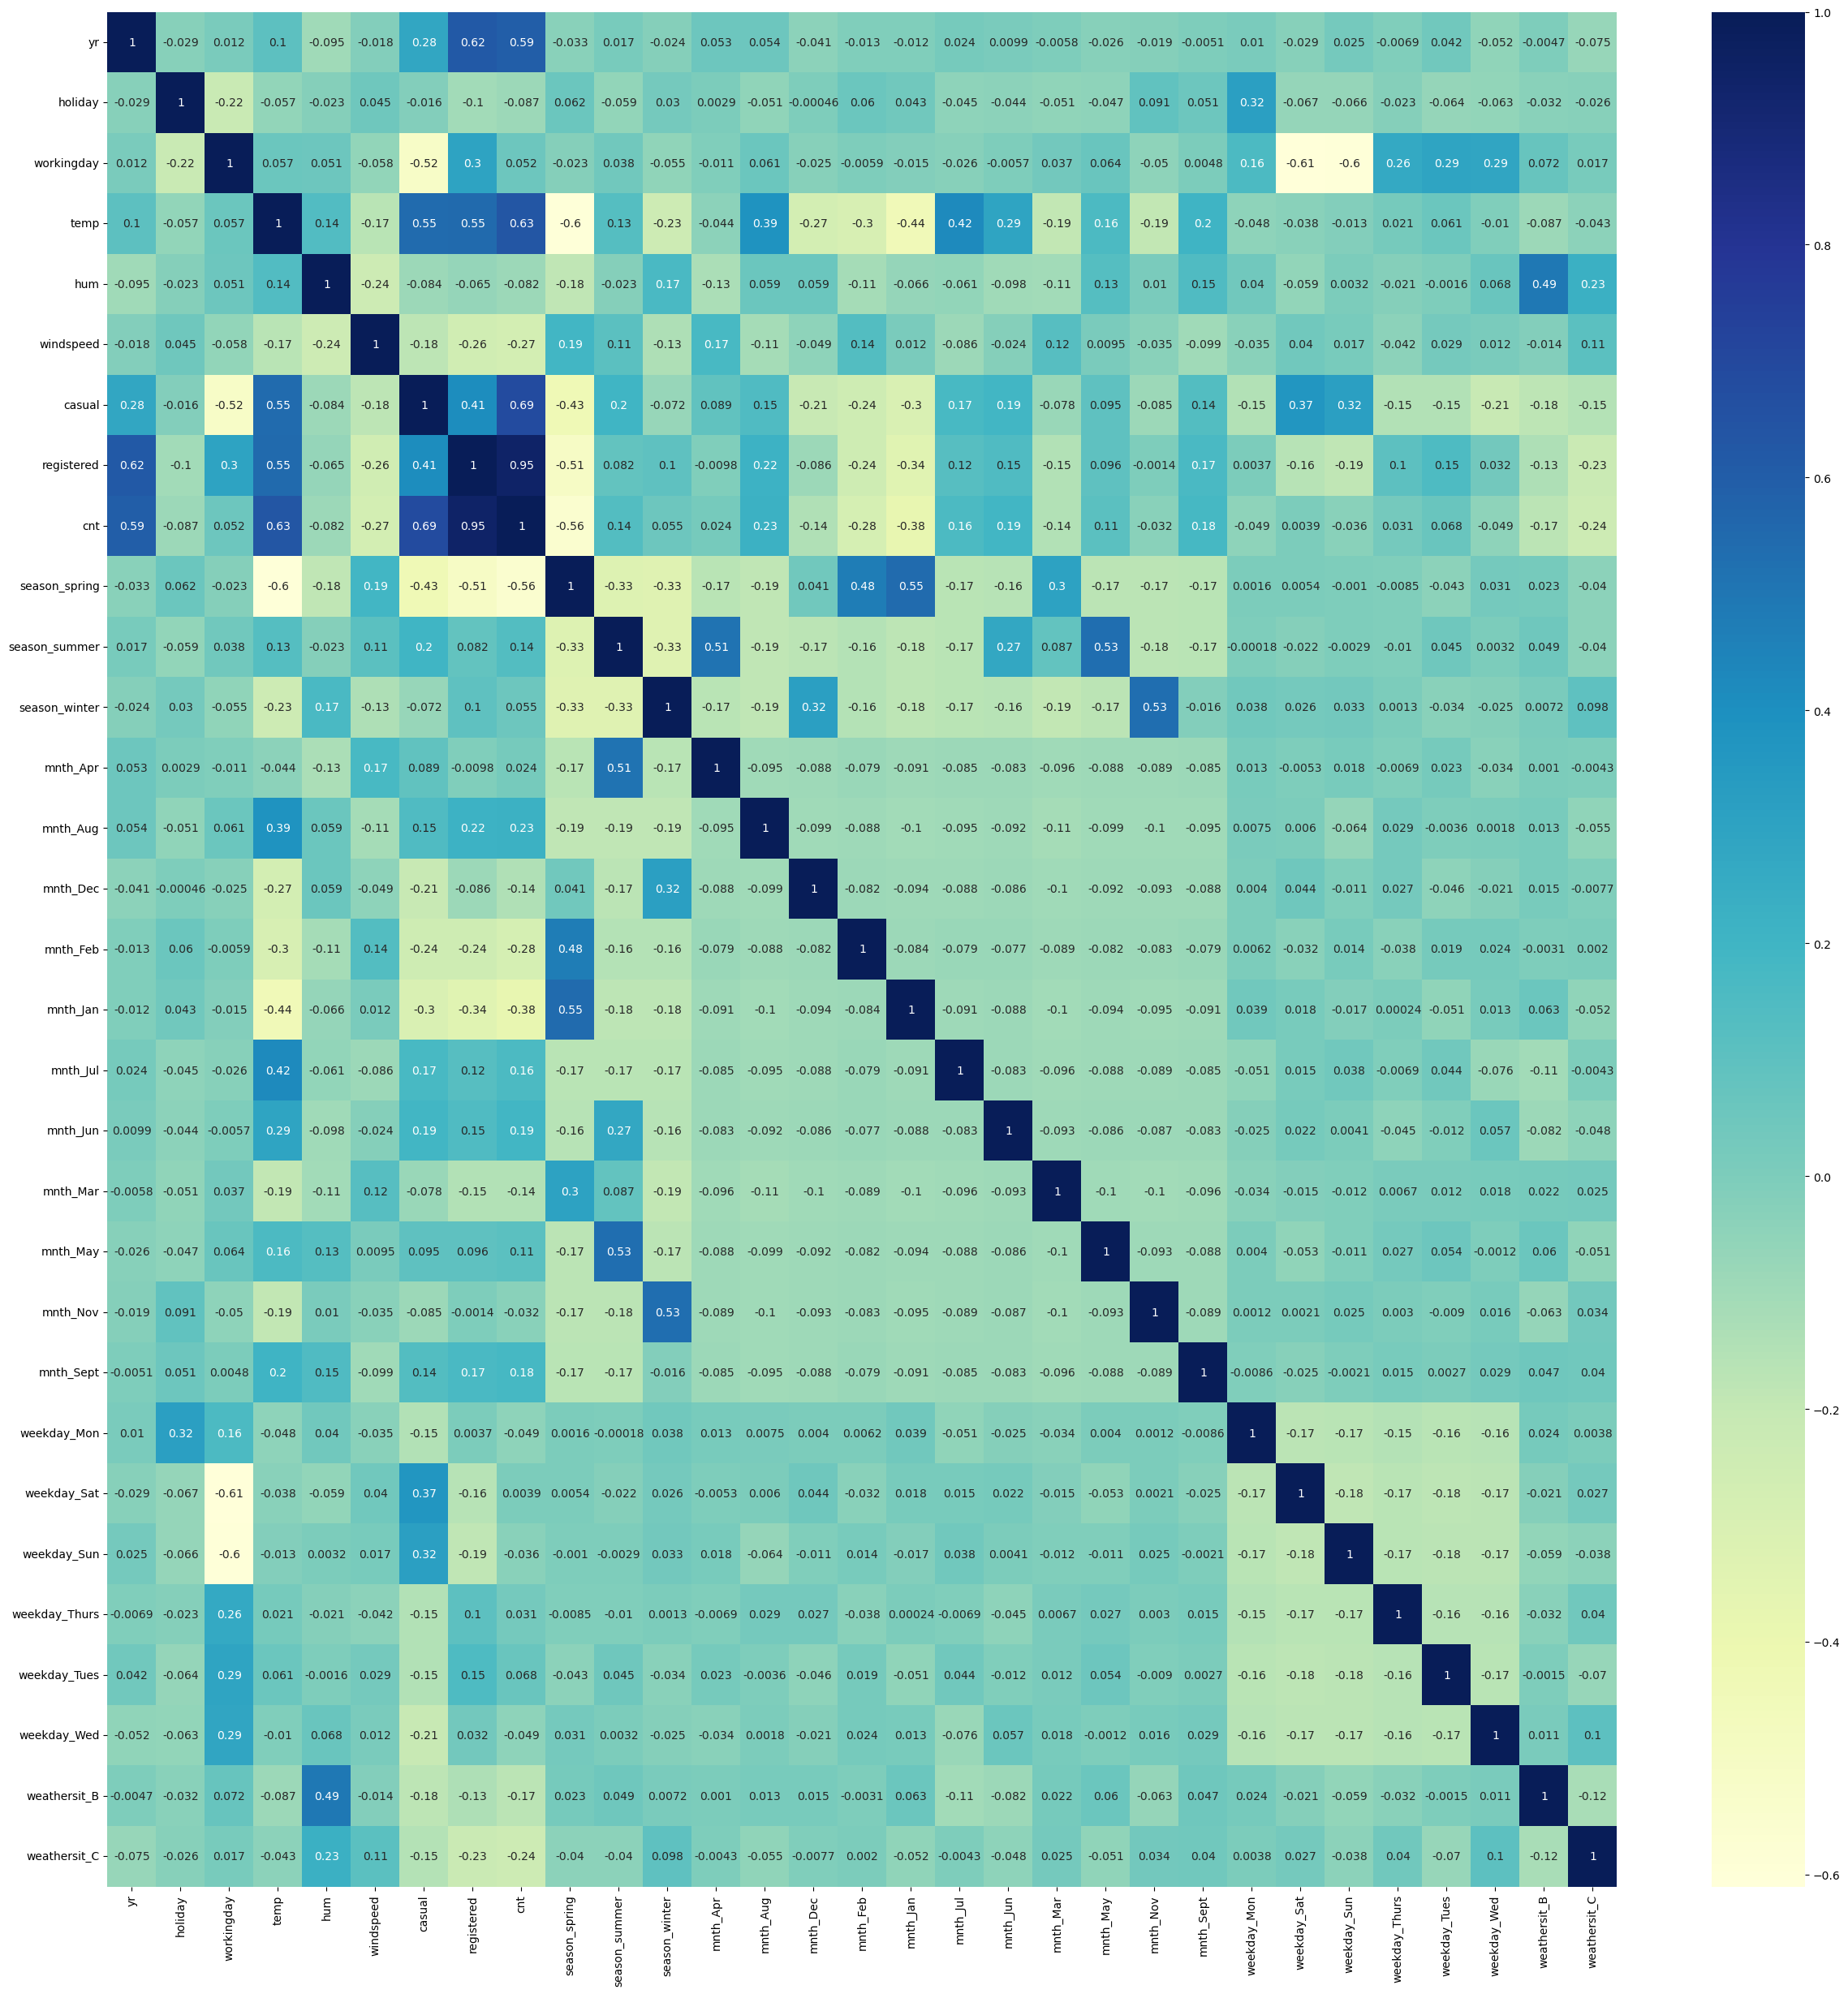

In [54]:
# Checking the coreelation coefficients to see which variables are highly corelated
plt.figure(figsize= (30,30))
sns.heatmap(df_train.corr(), annot = True, cmap="YlGnBu")
plt.show()

In [55]:
# Diving into X and y
x_train = df_train.drop(["casual", "registered"], axis=1)
y_train = df_train.pop('cnt')

x_train.head()

,yr,holiday,workingday,temp,hum,windspeed,cnt,season_spring,season_summer,season_winter,...,mnth_Nov,mnth_Sept,weekday_Mon,weekday_Sat,weekday_Sun,weekday_Thurs,weekday_Tues,weekday_Wed,weathersit_B,weathersit_C
576,1,0,1,0.836974,0.689137,0.239301,0.814887,False,False,False,...,False,False,True,False,False,False,False,False,False,False
426,1,0,1,0.366591,0.677114,0.220569,0.364933,True,False,False,...,False,False,False,False,False,False,False,False,True,False
729,1,0,0,0.245101,0.498067,0.663106,0.204096,True,False,False,...,False,False,False,False,True,False,False,False,False,False
482,1,0,1,0.496388,0.413052,0.656397,0.714565,False,True,False,...,False,False,False,False,False,False,False,False,False,False
111,0,0,1,0.345824,0.751824,0.380981,0.191095,False,True,False,...,False,False,False,False,False,False,False,False,True,False


In [56]:
# np.array(x_train)

In [57]:
print(x_train.dtypes)
print(y_train.dtypes)

yr                 int64
holiday            int64
workingday         int64
temp             float64
hum              float64
windspeed        float64
cnt              float64
season_spring       bool
season_summer       bool
season_winter       bool
mnth_Apr            bool
mnth_Aug            bool
mnth_Dec            bool
mnth_Feb            bool
mnth_Jan            bool
mnth_Jul            bool
mnth_Jun            bool
mnth_Mar            bool
mnth_May            bool
mnth_Nov            bool
mnth_Sept           bool
weekday_Mon         bool
weekday_Sat         bool
weekday_Sun         bool
weekday_Thurs       bool
weekday_Tues        bool
weekday_Wed         bool
weathersit_B        bool
weathersit_C        bool
dtype: object
float64


In [58]:
bool_cols = x_train.select_dtypes(include='bool').columns
x_train[bool_cols] = x_train[bool_cols].astype(int)

In [59]:
x_train = x_train.drop(['dteday'], axis=1, errors='ignore')

In [60]:
x_train = pd.get_dummies(x_train, drop_first=True)

In [61]:
y_train = pd.to_numeric(y_train, errors='coerce')

In [62]:
import statsmodels.api as sm
x_train_sm = sm.add_constant(x_train)   # add intercept
lr = sm.OLS(y_train, x_train_sm).fit()
lr.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    cnt   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 6.470e+29
Date:                Fri, 06 Mar 2026   Prob (F-statistic):               0.00
Time:                        19:28:15   Log-Likelihood:                 16848.
No. Observations:                 511   AIC:                        -3.364e+04
Df Residuals:                     482   BIC:                        -3.351e+04
Df Model:                          28                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const         -3.469e-16   5.29e-16     -0.656      0.512   -1.39e-15    6.92e-16
yr            -2.602e-16   1.82e-16     -1.429      0.154   -6.18e-16    9.75e-17
holiday       -2.151e-16   3.37e-16     -0.638      0.524   -8.78e-16    4.48e-16
workingday    -3.886e-16   1.82e-16     -2.140      0.033   -7.45e-16   -3.18e-17
temp           7.772e-16   6.75e-16      1.152      0.250   -5.49e-16     2.1e-15
hum            1.388e-17   5.21e-16      0.027      0.979   -1.01e-15    1.04e-15
windspeed      6.245e-17   3.76e-16      0.166      0.868   -6.77e-16    8.02e-16
cnt               1.0000    6.2e-16   1.61e+15      0.000       1.000       1.000
season_spring -1.631e-16   4.09e-16     -0.399      0.690   -9.67e-16    6.41e-16
season_summer  3.469e-16   3.59e-16      0.968      0.334   -3.58e-16    1.05e-15
season_winter -1.388e-17   3.83e-16     -0.036      0.971   -7.66e-16    7.39e-16
mnth_Apr      -1.249e-16   4.86e-16     -0.257      0.797   -1.08e-15     8.3e-16
mnth_Aug       5.204e-17    4.8e-16      0.108      0.914   -8.91e-16    9.95e-16
mnth_Dec       2.004e-16   3.01e-16      0.665      0.506   -3.92e-16    7.92e-16
mnth_Feb       6.939e-17    4.6e-16      0.151      0.880   -8.34e-16    9.73e-16
mnth_Jan       1.457e-16   4.67e-16      0.312      0.755   -7.73e-16    1.06e-15
mnth_Jul      -8.327e-17   5.03e-16     -0.165      0.869   -1.07e-15    9.06e-16
mnth_Jun      -3.886e-16   4.82e-16     -0.807      0.420   -1.34e-15    5.58e-16
mnth_Mar      -3.296e-17   4.23e-16     -0.078      0.938   -8.64e-16    7.98e-16
mnth_May      -1.631e-16   4.92e-16     -0.331      0.741   -1.13e-15    8.04e-16
mnth_Nov       3.192e-16   2.71e-16      1.176      0.240   -2.14e-16    8.52e-16
mnth_Sept     -8.327e-17   4.04e-16     -0.206      0.837   -8.77e-16     7.1e-16
weekday_Mon   -7.633e-17   2.12e-16     -0.361      0.719   -4.92e-16     3.4e-16
weekday_Sat   -1.249e-16   1.98e-16     -0.632      0.528   -5.13e-16    2.64e-16
weekday_Sun   -2.567e-16   1.97e-16     -1.306      0.192   -6.43e-16     1.3e-16
weekday_Thurs  -1.11e-16   2.06e-16     -0.539      0.590   -5.16e-16    2.94e-16
weekday_Tues  -1.457e-16   2.01e-16     -0.724      0.469   -5.41e-16     2.5e-16
weekday_Wed    2.498e-16   2.05e-16      1.221      0.223   -1.52e-16    6.52e-16
weathersit_B  -8.882e-16   1.47e-16     -6.059      0.000   -1.18e-15      -6e-16
weathersit_C  -4.857e-16      4e-16     -1.213      0.226   -1.27e-15    3.01e-16
==============================================================================
Omnibus:                       38.906   Durbin-Watson:                   0.387
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               19.152
Skew:                           0.288   Prob(JB):                     6.94e-05
Kurtosis:                       2.247   Cond. No.            

In [63]:
lr.params

const           -3.469447e-16
yr              -2.602085e-16
holiday         -2.151057e-16
workingday      -3.885781e-16
temp             7.771561e-16
hum              1.387779e-17
windspeed        6.245005e-17
cnt              1.000000e+00
season_spring   -1.630640e-16
season_summer    3.469447e-16
season_winter   -1.387779e-17
mnth_Apr        -1.249001e-16
mnth_Aug         5.204170e-17
mnth_Dec         2.003606e-16
mnth_Feb         6.938894e-17
mnth_Jan         1.457168e-16
mnth_Jul        -8.326673e-17
mnth_Jun        -3.885781e-16
mnth_Mar        -3.295975e-17
mnth_May        -1.630640e-16
mnth_Nov         3.191891e-16
mnth_Sept       -8.326673e-17
weekday_Mon     -7.632783e-17
weekday_Sat     -1.249001e-16
weekday_Sun     -2.567391e-16
weekday_Thurs   -1.110223e-16
weekday_Tues    -1.457168e-16
weekday_Wed      2.498002e-16
weathersit_B    -8.881784e-16
weathersit_C    -4.857226e-16
dtype: float64

In [64]:
lm = LinearRegression()

lm.fit(x_train, y_train)

LinearRegression()

In [65]:
print(lm.coef_)
print(lm.intercept_)

[ 3.92967955e-17  8.49112855e-16 -4.56487037e-16 -5.56566361e-16
  3.23619874e-16  3.09495659e-16  1.00000000e+00  3.29813292e-16
  3.71530338e-17  3.10981541e-16  1.73266330e-16  2.48578079e-16
 -7.30561305e-20 -4.10247418e-17  5.78916187e-18  3.49510959e-16
  1.63196264e-16 -2.58435673e-16  1.40093310e-16 -7.92229446e-17
  1.30600568e-16 -1.03738920e-16 -4.55214120e-16 -5.60493457e-16
  8.76184139e-17  1.11946614e-16 -5.53206801e-17  1.04231961e-16
  1.23403903e-16]
-1.1102230246251565e-16


In [66]:
lr.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    cnt   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 6.470e+29
Date:                Fri, 06 Mar 2026   Prob (F-statistic):               0.00
Time:                        19:28:15   Log-Likelihood:                 16848.
No. Observations:                 511   AIC:                        -3.364e+04
Df Residuals:                     482   BIC:                        -3.351e+04
Df Model:                          28                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const         -3.469e-16   5.29e-16     -0.656      0.512   -1.39e-15    6.92e-16
yr            -2.602e-16   1.82e-16     -1.429      0.154   -6.18e-16    9.75e-17
holiday       -2.151e-16   3.37e-16     -0.638      0.524   -8.78e-16    4.48e-16
workingday    -3.886e-16   1.82e-16     -2.140      0.033   -7.45e-16   -3.18e-17
temp           7.772e-16   6.75e-16      1.152      0.250   -5.49e-16     2.1e-15
hum            1.388e-17   5.21e-16      0.027      0.979   -1.01e-15    1.04e-15
windspeed      6.245e-17   3.76e-16      0.166      0.868   -6.77e-16    8.02e-16
cnt               1.0000    6.2e-16   1.61e+15      0.000       1.000       1.000
season_spring -1.631e-16   4.09e-16     -0.399      0.690   -9.67e-16    6.41e-16
season_summer  3.469e-16   3.59e-16      0.968      0.334   -3.58e-16    1.05e-15
season_winter -1.388e-17   3.83e-16     -0.036      0.971   -7.66e-16    7.39e-16
mnth_Apr      -1.249e-16   4.86e-16     -0.257      0.797   -1.08e-15     8.3e-16
mnth_Aug       5.204e-17    4.8e-16      0.108      0.914   -8.91e-16    9.95e-16
mnth_Dec       2.004e-16   3.01e-16      0.665      0.506   -3.92e-16    7.92e-16
mnth_Feb       6.939e-17    4.6e-16      0.151      0.880   -8.34e-16    9.73e-16
mnth_Jan       1.457e-16   4.67e-16      0.312      0.755   -7.73e-16    1.06e-15
mnth_Jul      -8.327e-17   5.03e-16     -0.165      0.869   -1.07e-15    9.06e-16
mnth_Jun      -3.886e-16   4.82e-16     -0.807      0.420   -1.34e-15    5.58e-16
mnth_Mar      -3.296e-17   4.23e-16     -0.078      0.938   -8.64e-16    7.98e-16
mnth_May      -1.631e-16   4.92e-16     -0.331      0.741   -1.13e-15    8.04e-16
mnth_Nov       3.192e-16   2.71e-16      1.176      0.240   -2.14e-16    8.52e-16
mnth_Sept     -8.327e-17   4.04e-16     -0.206      0.837   -8.77e-16     7.1e-16
weekday_Mon   -7.633e-17   2.12e-16     -0.361      0.719   -4.92e-16     3.4e-16
weekday_Sat   -1.249e-16   1.98e-16     -0.632      0.528   -5.13e-16    2.64e-16
weekday_Sun   -2.567e-16   1.97e-16     -1.306      0.192   -6.43e-16     1.3e-16
weekday_Thurs  -1.11e-16   2.06e-16     -0.539      0.590   -5.16e-16    2.94e-16
weekday_Tues  -1.457e-16   2.01e-16     -0.724      0.469   -5.41e-16     2.5e-16
weekday_Wed    2.498e-16   2.05e-16      1.221      0.223   -1.52e-16    6.52e-16
weathersit_B  -8.882e-16   1.47e-16     -6.059      0.000   -1.18e-15      -6e-16
weathersit_C  -4.857e-16      4e-16     -1.213      0.226   -1.27e-15    3.01e-16
==============================================================================
Omnibus:                       38.906   Durbin-Watson:                   0.387
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               19.152
Skew:                           0.288   Prob(JB):                     6.94e-05
Kurtosis:                       2.247   Cond. No.            

In [67]:

from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import RFE


In [68]:


lm = LinearRegression()

rfe1 = RFE(estimator=lm, n_features_to_select=15)

rfe1.fit(x_train, y_train)

print(rfe1.support_)
print(rfe1.ranking_)

[ True  True  True  True False False  True False  True  True False False
 False  True  True False  True  True False False False  True False False
  True  True False False  True]
[ 1  1  1  1  6 12  1  7  1  1 10  2 15  1  1  9  1  1  4  5 13  1  3  8
  1  1 11 14  1]


In [69]:
col1 = x_train.columns[rfe1.support_]

col1

Index(['yr', 'holiday', 'workingday', 'temp', 'cnt', 'season_summer',
       'season_winter', 'mnth_Feb', 'mnth_Jan', 'mnth_Jun', 'mnth_Mar',
       'weekday_Mon', 'weekday_Thurs', 'weekday_Tues', 'weathersit_C'],
      dtype='object')

In [70]:
x_train_rfe1 = x_train[col1]

x_train_rfe1 = sm.add_constant(x_train_rfe1)
lm1 = sm.OLS(y_train, x_train_rfe1).fit()
lm1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    cnt   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 9.860e+30
Date:                Fri, 06 Mar 2026   Prob (F-statistic):               0.00
Time:                        19:28:16   Log-Likelihood:                 17378.
No. Observations:                 511   AIC:                        -3.472e+04
Df Residuals:                     495   BIC:                        -3.466e+04
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const          2.255e-16   1.11e-16      2.028      0.043    6.98e-18    4.44e-16
yr            -1.093e-16   5.65e-17     -1.933      0.054    -2.2e-16    1.77e-18
holiday        4.163e-16   1.38e-16      3.022      0.003    1.46e-16    6.87e-16
workingday     4.163e-17   4.87e-17      0.855      0.393   -5.41e-17    1.37e-16
temp          -3.331e-16   1.69e-16     -1.976      0.049   -6.64e-16   -1.91e-18
cnt               1.0000   1.79e-16    5.6e+15      0.000       1.000       1.000
season_summer  3.053e-16   5.38e-17      5.673      0.000       2e-16    4.11e-16
season_winter  1.041e-17    6.8e-17      0.153      0.878   -1.23e-16    1.44e-16
mnth_Feb      -9.368e-17   1.01e-16     -0.925      0.355   -2.93e-16    1.05e-16
mnth_Jan      -3.192e-16   1.03e-16     -3.100      0.002   -5.22e-16   -1.17e-16
mnth_Jun       1.422e-16   7.71e-17      1.846      0.066   -9.17e-18    2.94e-16
mnth_Mar      -2.498e-16   7.69e-17     -3.249      0.001   -4.01e-16   -9.87e-17
weekday_Mon    -7.98e-17   6.43e-17     -1.241      0.215   -2.06e-16    4.65e-17
weekday_Thurs -5.551e-17    6.2e-17     -0.895      0.371   -1.77e-16    6.63e-17
weekday_Tues   3.261e-16   6.02e-17      5.417      0.000    2.08e-16    4.44e-16
weathersit_C  -4.718e-16   1.25e-16     -3.785      0.000   -7.17e-16   -2.27e-16
==============================================================================
Omnibus:                        0.495   Durbin-Watson:                   0.767
Prob(Omnibus):                  0.781   Jarque-Bera (JB):                0.360
Skew:                          -0.053   Prob(JB):                        0.835
Kurtosis:                       3.075   Cond. No.                         20.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [71]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

a = x_train_rfe1.drop('const', axis=1)

In [72]:



a = a.select_dtypes(include=[np.number])

a = a.replace([np.inf, -np.inf], np.nan)
a = a.dropna()

vif = pd.DataFrame()
vif["features"] = a.columns
vif["VIF"] = [variance_inflation_factor(a.values, i) for i in range(a.shape[1])]
vif["VIF"] = round(vif["VIF"], 2)

vif = vif.sort_values(by="VIF", ascending=False)
vif

,features,VIF
4,cnt,28.87
3,temp,16.00
0,yr,4.73
2,workingday,4.49
6,season_winter,1.91
5,season_summer,1.67
11,weekday_Mon,1.63
13,weekday_Tues,1.55
12,weekday_Thurs,1.49
1,holiday,1.29


In [73]:
lm = LinearRegression()

rfe2 = RFE(estimator=lm, n_features_to_select=7)

rfe2.fit(x_train, y_train)

print(rfe2.support_)
print(rfe2.ranking_)

[False False False  True False False  True False False  True False False
 False  True  True False False  True False False False False False False
 False False False False  True]
[ 9  6  2  1 14 20  1 15  4  1 18 10 23  1  1 17  7  1 12 13 21  5 11 16
  8  3 19 22  1]


In [74]:
col2 = x_train.columns[rfe2.support_]

x_train_rfe2 = x_train[col2]

x_train_rfe2= sm.add_constant(x_train_rfe2)
lm2 = sm.OLS(y_train, x_train_rfe2).fit()
lm2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    cnt   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 2.113e+31
Date:                Fri, 06 Mar 2026   Prob (F-statistic):               0.00
Time:                        19:28:16   Log-Likelihood:                 17373.
No. Observations:                 511   AIC:                        -3.473e+04
Df Residuals:                     503   BIC:                        -3.470e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const         -2.446e-16   9.59e-17     -2.551      0.011   -4.33e-16   -5.62e-17
temp          -2.082e-16   1.45e-16     -1.433      0.152   -4.94e-16    7.72e-17
cnt               1.0000   1.17e-16   8.55e+15      0.000       1.000       1.000
season_winter  1.839e-16   5.72e-17      3.215      0.001    7.15e-17    2.96e-16
mnth_Feb       -2.29e-16   9.22e-17     -2.483      0.013    -4.1e-16   -4.78e-17
mnth_Jan      -1.501e-16   9.24e-17     -1.624      0.105   -3.32e-16    3.14e-17
mnth_Mar      -4.857e-17   7.49e-17     -0.649      0.517   -1.96e-16    9.86e-17
weathersit_C  -1.388e-17    1.2e-16     -0.115      0.908    -2.5e-16    2.22e-16
==============================================================================
Omnibus:                       44.519   Durbin-Watson:                   0.193
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               42.775
Skew:                          -0.647   Prob(JB):                     5.15e-10
Kurtosis:                       2.424   Cond. No.                         13.6
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [75]:


b = x_train_rfe2.drop('const', axis=1)

b = b.apply(pd.to_numeric, errors='coerce')

b = b.astype(float)

b = b.replace([np.inf, -np.inf], np.nan)
b = b.dropna()

vif1 = pd.DataFrame()
vif1["features"] = b.columns
vif1["VIF"] = [variance_inflation_factor(b.values, i) for i in range(b.shape[1])]
vif1["VIF"] = round(vif1["VIF"], 2)

vif1 = vif1.sort_values(by="VIF", ascending=False)

vif1

,features,VIF
1,cnt,11.91
0,temp,10.49
2,season_winter,1.50
6,weathersit_C,1.14
5,mnth_Mar,1.09
4,mnth_Jan,1.03
3,mnth_Feb,1.03


In [76]:
print(y_train.head())

576    0.814887
426    0.364933
729    0.204096
482    0.714565
111    0.191095
Name: cnt, dtype: float64


In [77]:
y_train_cnt = lm2.predict(x_train_rfe2)



<Axes: ylabel='Density'>

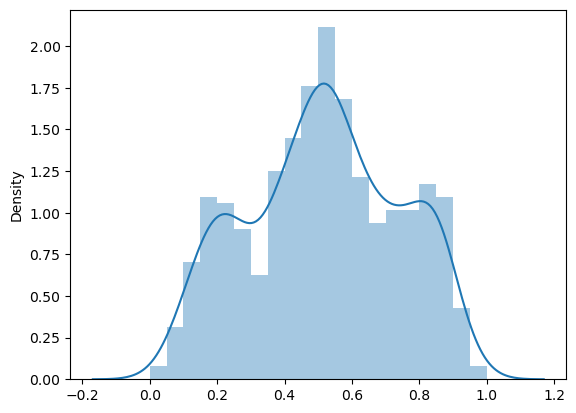

In [78]:
fig = plt.figure()
sns.distplot((y_train, y_train_cnt), bins=20)

In [79]:
df_test[var]=scaler.transform(df_test[var])
df_test

,yr,holiday,workingday,temp,hum,windspeed,casual,registered,cnt,season_spring,...,mnth_Nov,mnth_Sept,weekday_Mon,weekday_Sat,weekday_Sun,weekday_Thurs,weekday_Tues,weekday_Wed,weathersit_B,weathersit_C
184,0,1,0,0.831783,0.657364,0.084219,0.942462,0.435000,0.692706,False,...,False,False,True,False,False,False,False,False,True,False
535,1,0,1,0.784017,0.711035,0.227262,0.297231,0.858382,0.782674,False,...,False,False,False,False,False,False,True,False,False,False
299,0,0,1,0.511964,0.837699,0.334206,0.073231,0.352794,0.303382,False,...,False,False,False,False,False,True,False,False,True,False
221,0,0,1,0.881625,0.437098,0.339570,0.271385,0.570000,0.547400,False,...,False,False,False,False,False,False,False,True,False,False
152,0,0,1,0.817246,0.314298,0.537414,0.225846,0.619412,0.569029,False,...,False,False,False,False,False,True,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
702,1,0,1,0.490158,0.790897,0.086888,0.170154,0.832206,0.714680,False,...,False,False,True,False,False,False,False,False,False,False
127,0,0,0,0.584649,0.650923,0.069510,0.430462,0.428235,0.495973,False,...,False,False,False,False,True,False,False,False,False,False
640,1,0,1,0.662528,0.898240,0.133655,0.096308,0.632941,0.531178,False,...,False,False,False,False,False,False,True,False,False,True
72,0,0,1,0.331557,0.512107,0.203418,0.109846,0.245147,0.232858,True,...,False,False,True,False,False,False,False,False,False,False


In [80]:
y_test = df_test.pop('cnt')
x_test = df_test.drop(["casual", "registered"], axis=1)

x_test.head()

,yr,holiday,workingday,temp,hum,windspeed,season_spring,season_summer,season_winter,mnth_Apr,...,mnth_Nov,mnth_Sept,weekday_Mon,weekday_Sat,weekday_Sun,weekday_Thurs,weekday_Tues,weekday_Wed,weathersit_B,weathersit_C
184,0,1,0,0.831783,0.657364,0.084219,False,False,False,False,...,False,False,True,False,False,False,False,False,True,False
535,1,0,1,0.784017,0.711035,0.227262,False,True,False,False,...,False,False,False,False,False,False,True,False,False,False
299,0,0,1,0.511964,0.837699,0.334206,False,False,True,False,...,False,False,False,False,False,True,False,False,True,False
221,0,0,1,0.881625,0.437098,0.339570,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
152,0,0,1,0.817246,0.314298,0.537414,False,True,False,False,...,False,False,False,False,False,True,False,False,False,False


In [81]:

c = x_train_rfe2.drop('const', axis=1)

In [82]:
col2 = c.columns

In [83]:
x_test.columns.tolist()

['yr',
 'holiday',
 'workingday',
 'temp',
 'hum',
 'windspeed',
 'season_spring',
 'season_summer',
 'season_winter',
 'mnth_Apr',
 'mnth_Aug',
 'mnth_Dec',
 'mnth_Feb',
 'mnth_Jan',
 'mnth_Jul',
 'mnth_Jun',
 'mnth_Mar',
 'mnth_May',
 'mnth_Nov',
 'mnth_Sept',
 'weekday_Mon',
 'weekday_Sat',
 'weekday_Sun',
 'weekday_Thurs',
 'weekday_Tues',
 'weekday_Wed',
 'weathersit_B',
 'weathersit_C']

In [84]:
col2 = [c for c in col2 if c in x_test.columns]
x_test_rfe2 = x_test[col2]

In [85]:
x_test_rfe2 = x_test[col2]
x_test_rfe2 = sm.add_constant(x_test_rfe2)
x_test_rfe2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 220 entries, 184 to 653
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   const          220 non-null    float64
 1   temp           220 non-null    float64
 2   season_winter  220 non-null    bool   
 3   mnth_Feb       220 non-null    bool   
 4   mnth_Jan       220 non-null    bool   
 5   mnth_Mar       220 non-null    bool   
 6   weathersit_C   220 non-null    bool   
dtypes: bool(5), float64(2)
memory usage: 6.2 KB
